In [24]:
pip install tensorflow matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten


In [26]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


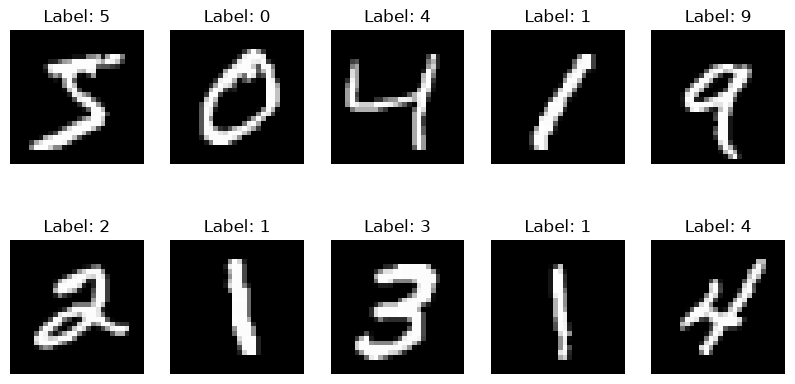

In [27]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [28]:
X_train = X_train / 255.0
X_test = X_test / 255.0


In [29]:
model = Sequential([

    Flatten(input_shape=(28, 28)),

    Dense(200, activation='relu'),

    Dense(100, activation='relu'),

    Dense(10, activation='softmax')

])

In [30]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9306 - loss: 0.2357 - val_accuracy: 0.9597 - val_loss: 0.1312
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9704 - loss: 0.0970 - val_accuracy: 0.9695 - val_loss: 0.0971
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9801 - loss: 0.0639 - val_accuracy: 0.9762 - val_loss: 0.0865
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9848 - loss: 0.0469 - val_accuracy: 0.9709 - val_loss: 0.1015
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9878 - loss: 0.0372 - val_accuracy: 0.9722 - val_loss: 0.1055


In [32]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9719 - loss: 0.0952
Test Accuracy: 97.18999862670898 %


In [33]:
prediction = model.predict(X_test)

digit = np.argmax(prediction[1])

print("Predicted digit:", digit)
print("Actual digit:", y_test[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predicted digit: 2
Actual digit: 2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


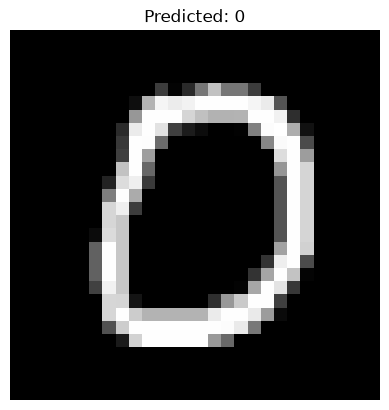

Actual digit: 0


In [34]:
index = 10

prediction = model.predict(
    X_test[index:index+1]
)

predicted_digit = np.argmax(prediction)

plt.imshow(X_test[index], cmap='gray')
plt.title(f"Predicted: {predicted_digit}")
plt.axis('off')
plt.show()

print("Actual digit:", y_test[index])

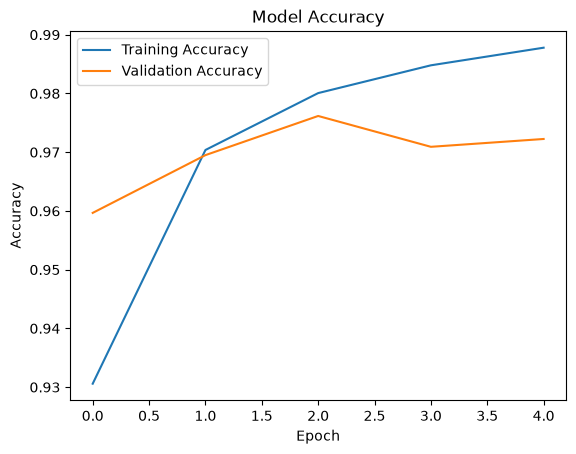

In [35]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()